# XGBoost forecasts of next-month realized variance
Per ETF (XLB, XLE, XLF, XLI, XLY), expanding window.

**Question:** does macro information help, and does it still help once VIX is removed?

| Section | What it does |
|---|---|
| 1. Settings | paths, ETFs, grid, input sets |
| 2. Data | monthly log realized variance + lagged inputs |
| 3. Model | tuning, walk-forward, OLS benchmark, scores |
| 4. Run | all ETFs and input sets (slow) |
| 5. Results | MSE, R2_OOS, QLIKE tables |
| 6. Save | forecast CSV in the Elastic Net layout |
| 7. Push | which inputs drive the forecasts |
| 8. Tree | look inside one tree |
| 9. Clark-West | are the gains from adding inputs statistically significant? |

Run the cells in order. Cell 4 takes the longest.

## 1. Settings  (the only cell you normally need to edit)

Everything you normally edit lives here: file paths, the 5 ETFs, the first forecast month, the training window, the tuning grid, and the **input sets** being compared. `LAGS` are the past-volatility inputs (last month, 3-month average, 12-month average); the macro sets add VIX and the other macro variables on top.

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
from xgboost import XGBRegressor, DMatrix
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore")

DATA = "/Users/lyc/Documents/GitHub/dse4101capstone-project/dataset"
RETURNS_PATH = DATA + "/price/clean/daily_returns_panel_ver2.csv"
MACRO_PATH = DATA + "/macro_variables/final_clean/final_macro_data.csv"

ETFS = ["XLB", "XLE", "XLF", "XLI", "XLY"]
FIRST_MONTH = "2003-02-28"     # first month used as a TARGET. Jan 2003 (one trading day) is never a target;
                               # it is only the own-lag input of the Feb 2003 row, as in Elastic Net.
                               # Use "2003-03-31" to drop it completely (214 forecasts instead of 215).
MIN_TRAIN = 60                 # months in the first training window
RETUNE_EVERY = 24              # re-pick the tuning settings every 24 months (refit every month)
DROP_ONE = False               # True = also drop each macro variable one at a time (run super slow)

MACRO = ["T10Y2Y", "DGS3MO", "BAA10Y", "CPIAUCSL", "T5YIE", "T5YIE_MINUS_T10YIE",
         "VIXCLS", "INDPRO", "UNRATE", "UMCSENT", "DCOILWTICO"]

# Shallow trees, strong shrinkage, small grid (8 combinations)
GRID = [dict(max_depth=d, learning_rate=lr, n_estimators=n)
        for d, lr, n in itertools.product([2, 3], [0.01, 0.03], [100, 300])]                    # 8 dictionaries
FIXED = dict(subsample=0.7, colsample_bytree=0.8, min_child_weight=3, reg_lambda=5,
             n_jobs=1, random_state=4101, verbosity=0)

# Past-volatility inputs (HAR style): last month, the average of the last 3 months, the average of the last 12 months
LAGS = ["own_lag", "avg3", "avg12"]                     #own lag is last month value of the thing im predicting

# The input sets we compare
no_vix = [m for m in MACRO if m != "VIXCLS"]
INPUT_SETS = {
    "1 Lags only":         LAGS,
    "2 + VIX only":        LAGS + ["VIXCLS"],
    "3 Macro without VIX": LAGS + no_vix,
    "4 All macro":         LAGS + MACRO,
}
if DROP_ONE:
    for m in MACRO:
        INPUT_SETS[f"All minus {m}"] = LAGS + [x for x in MACRO if x != m]

## 2. Build the monthly data: target = log realized variance of month t, inputs known at t-1

Builds one monthly table per ETF. The target is the **log realized variance** of month *t* (sum of squared daily excess returns). Every input is dated *t-1* (`.shift(1)`), so the model never sees the month it forecasts.

In [2]:
daily = pd.read_csv(RETURNS_PATH, parse_dates=["date"]).set_index("date")
month = daily.index.to_period("M").to_timestamp("M")

macro = pd.read_csv(MACRO_PATH, parse_dates=["date"]).set_index("date")
macro.index = macro.index + pd.offsets.MonthEnd(0)
macro = macro[MACRO].shift(1)                      # macro from month t-1 predicts month t, shift moves every value down one row

data = {}
for etf in ETFS:
    rv = (daily["xret_" + etf] ** 2).groupby(month).sum()                     # excess returns, all months
    df = pd.DataFrame({"log_rv": np.log(rv)})
    past = df["log_rv"].shift(1)                   # everything below uses months before t only
    df["own_lag"] = past                           # last month's log realized variance
    df["avg3"] = past.rolling(3, min_periods=1).mean()     # average of the last 3 months
    df["avg12"] = past.rolling(12, min_periods=1).mean()   # average of the last 12 months
    data[etf] = df.join(macro).dropna().loc[FIRST_MONTH:]  # attaches macro column, keep rows from feb 2003 onwards
print({etf: len(df) for etf, df in data.items()}, "monthly rows per ETF")

{'XLB': 275, 'XLE': 275, 'XLF': 275, 'XLI': 275, 'XLY': 275} monthly rows per ETF


## 3. The model

The model code. `tune` picks the best of 8 XGBoost settings with 5-fold CV; `walk_forward` trains on all months before *t*, forecasts month *t*, then moves on one month (expanding window); `walk_forward_ols` is the plain OLS HAR benchmark; `score` computes MSE, R2_OOS and QLIKE.

In [3]:
def tune(X, y):
    """Pick the best grid setting with 5-fold CV (no shuffling) inside the training window."""
    best = None
    for params in GRID:
        pred = np.zeros(len(y))
        for train, valid in KFold(5).split(X):
            pred[valid] = XGBRegressor(**FIXED, **params).fit(X[train], y[train]).predict(X[valid])
        mse = np.mean((y - pred) ** 2)
        if best is None or mse < best[0]:
            best = (mse, params, np.var(y - pred, ddof=1)) # divide by n-1 to correct for bias
    return best[1], best[2]                        # best settings, CV residual variance (sigma2)


def walk_forward(df, inputs):
    """Expanding window: train on months before t, forecast month t, then move on one month."""
    X, y = df[inputs].to_numpy(float), df["log_rv"].to_numpy(float)
    rows = []
    for t in range(MIN_TRAIN, len(df)):
        if (t - MIN_TRAIN) % RETUNE_EVERY == 0:
            params, sigma2 = tune(X[:t], y[:t])
        model = XGBRegressor(**FIXED, **params).fit(X[:t], y[:t])
        pred = model.predict(X[t:t + 1])[0]
        # how much each input pushed this forecast up or down (SHAP values, built into xgboost)
        push = model.get_booster().predict(DMatrix(X[t:t + 1]), pred_contribs=True)[0][:-1]
        rows.append({"date": df.index[t], "actual": y[t], "pred": pred,
                     "level_pred": np.exp(pred + sigma2 / 2),     # log-normal correction
                     "sigma2": sigma2,
                     **{"push_" + c: v for c, v in zip(inputs, push)}})
    return pd.DataFrame(rows).set_index("date")


def walk_forward_ols(df, inputs):
    """Same expanding window, but plain OLS (no trees, no tuning). The simple HAR-style benchmark."""
    X, y = df[inputs].to_numpy(float), df["log_rv"].to_numpy(float)
    rows = []
    for t in range(MIN_TRAIN, len(df)):
        A = np.column_stack([np.ones(t), X[:t]])                  # add an intercept
        beta = np.linalg.lstsq(A, y[:t], rcond=None)[0]
        sigma2 = np.sum((y[:t] - A @ beta) ** 2) / (t - A.shape[1])   # residual variance of the training window
        pred = np.r_[1.0, X[t]] @ beta
        rows.append({"date": df.index[t], "actual": y[t], "pred": pred,
                     "level_pred": np.exp(pred + sigma2 / 2), "sigma2": sigma2})
    return pd.DataFrame(rows).set_index("date")


def score(fc, df):
    err = fc["actual"] - fc["pred"]
    benchmark = df["log_rv"].expanding().mean().shift(1).loc[fc.index]   # historical mean
    ratio = np.exp(fc["actual"]) / fc["level_pred"]
    return {"MSE": (err ** 2).mean(),                                    # log RV
            "R2_OOS": 1 - (err ** 2).sum() / ((fc["actual"] - benchmark) ** 2).sum(),
            "QLIKE": (ratio - np.log(ratio) - 1).mean()}                 # RV level

## 4. Run every input set for every ETF (takes several minutes)

Runs every input set for every ETF. **Slow:** expect tens of minutes. Nothing prints until the first ETF finishes.

In [4]:
forecasts, rows = {}, []
for etf in ETFS:
    for name, inputs in INPUT_SETS.items():
        forecasts[(name, etf)] = walk_forward(data[etf], inputs)
        rows.append({"etf": etf, "inputs": name, **score(forecasts[(name, etf)], data[etf])})
    # OLS benchmark: HAR lags only, no macro
    forecasts[("OLS HAR lags", etf)] = walk_forward_ols(data[etf], LAGS)
    rows.append({"etf": etf, "inputs": "OLS HAR lags", **score(forecasts[("OLS HAR lags", etf)], data[etf])})
    print(etf, "done")
results = pd.DataFrame(rows)

XLB done
XLE done
XLF done
XLI done
XLY done


## 5. Results: one table per loss. Compare columns within a row.

Results tables, one per loss. Compare columns within a row. MSE and QLIKE: lower is better. R2_OOS: higher is better. The last table shows what VIX adds on top of the other macro variables (set 4 minus set 3).

In [5]:
for metric, better in [("MSE", "lower"), ("R2_OOS", "higher"), ("QLIKE", "lower")]:
    print(f"\n{metric} ({better} is better)")
    print(results.pivot(index="etf", columns="inputs", values=metric)
          .loc[ETFS, list(INPUT_SETS) + ["OLS HAR lags"]].round(3))

# What does VIX add on top of the other macro variables?  (4 minus 3)
cols = ["MSE", "R2_OOS", "QLIKE"]
with_vix = results[results.inputs == "4 All macro"].set_index("etf")[cols]
without_vix = results[results.inputs == "3 Macro without VIX"].set_index("etf")[cols]
print("\nAdding VIX to the other macro variables (set 4 minus set 3):")
print((with_vix - without_vix).loc[ETFS].round(3))


MSE (lower is better)
inputs  1 Lags only  2 + VIX only  3 Macro without VIX  4 All macro  \
etf                                                                   
XLB           0.541         0.449                0.493        0.450   
XLE           0.481         0.474                0.466        0.462   
XLF           0.694         0.633                0.642        0.585   
XLI           0.562         0.447                0.503        0.450   
XLY           0.555         0.510                0.501        0.469   

inputs  OLS HAR lags  
etf                   
XLB            0.479  
XLE            0.447  
XLF            0.632  
XLI            0.522  
XLY            0.548  

R2_OOS (higher is better)
inputs  1 Lags only  2 + VIX only  3 Macro without VIX  4 All macro  \
etf                                                                   
XLB           0.354         0.464                0.411        0.462   
XLE           0.488         0.496                0.505        0.509   
XLF    

## 6. Save our forecasts in the same layout as EN

Saves the forecasts to your Desktop in the same layout as the Elastic Net file (`model, etf, date, actual_logRV, actual_RV, fc_log, sigma2, fc_level`). `date` is the forecast origin, the month before the month being forecast.

In [6]:
# Columns: model, etf, date, actual_logRV, actual_RV, fc_log, sigma2, fc_level
# date = forecast ORIGIN (the month before the month being forecast), as in her file.
# The file is saved automatically on your Desktop (found with ~), so no path to type.
import os

NAMES = {"OLS HAR lags": "ols_har_no_macro", "1 Lags only": "xgb_no_macro", "2 + VIX only": "xgb_vix_only",
         "3 Macro without VIX": "xgb_no_vix", "4 All macro": "xgb_full_macro"}
tidy = []
for (name, etf), fc in forecasts.items():
    tidy.append(pd.DataFrame({
        "model": NAMES.get(name, "xgb_" + name), "etf": etf,
        "date": fc.index - pd.offsets.MonthEnd(1),
        "actual_logRV": fc["actual"].values, "actual_RV": np.exp(fc["actual"].values),
        "fc_log": fc["pred"].values, "sigma2": fc["sigma2"].values, "fc_level": fc["level_pred"].values}))
tidy = pd.concat(tidy, ignore_index=True)

out_dir = os.path.expanduser("~/Desktop")
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, "xgb_forecasts_expanding_tidy.csv")
tidy.to_csv(out_file, index=False)
print("\nSaved", tidy.shape, "->", os.path.abspath(out_file))


Saved (5375, 8) -> /Users/lyc/Desktop/xgb_forecasts_expanding_tidy.csv


## 7. How much does each input move the forecast?  (average size of its push, in log variance)

How much each input moved the forecasts (SHAP "push", in log variance), averaged over all months, then as a share of the total.

In [7]:
full = "4 All macro"
push = pd.DataFrame({etf: forecasts[(full, etf)].filter(like="push_").abs().mean() for etf in ETFS})
push.index = push.index.str.replace("push_", "")
push["average"] = push.mean(axis=1)
print("\nAverage push of each input on the forecast (set 4):")
print(push.sort_values("average", ascending=False).round(3))
print("\nShare of the total push:")
print((push / push.sum() * 100).sort_values("average", ascending=False).round(1))


Average push of each input on the forecast (set 4):
                      XLB    XLE    XLF    XLI    XLY  average
VIXCLS              0.240  0.052  0.293  0.330  0.305    0.244
own_lag             0.125  0.211  0.213  0.108  0.176    0.167
avg3                0.086  0.139  0.145  0.067  0.045    0.096
UMCSENT             0.053  0.093  0.107  0.074  0.121    0.089
avg12               0.054  0.105  0.090  0.047  0.041    0.067
BAA10Y              0.088  0.025  0.087  0.067  0.069    0.067
CPIAUCSL            0.061  0.055  0.071  0.061  0.070    0.064
DCOILWTICO          0.060  0.057  0.075  0.046  0.055    0.059
DGS3MO              0.045  0.053  0.042  0.039  0.060    0.048
T5YIE               0.048  0.053  0.042  0.043  0.038    0.045
T5YIE_MINUS_T10YIE  0.038  0.040  0.040  0.046  0.045    0.042
T10Y2Y              0.023  0.042  0.042  0.031  0.031    0.034
UNRATE              0.027  0.026  0.029  0.042  0.029    0.031
INDPRO              0.027  0.029  0.037  0.019  0.022    0.027

S

## 8. Look at one tree (fit once on the full sample, only to look inside)

Fits one model on the full sample only to look inside, and prints the first tree. The picture needs Graphviz; the text tree has the same information.


First tree for XLF:
0:[own_lag<-2.84809065] yes=1,no=2,missing=1
	1:leaf=-0.192998335
	2:leaf=-0.0502876006

No picture (Graphviz not installed). The text tree above has the same information.


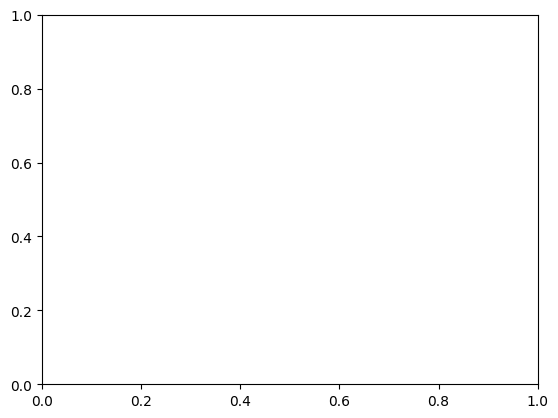

In [8]:
TREE_ETF = "XLF"
inputs = INPUT_SETS[full]
tree = XGBRegressor(**FIXED, max_depth=2, learning_rate=0.03, n_estimators=300)
tree.fit(data[TREE_ETF][inputs], data[TREE_ETF]["log_rv"])
print(f"\nFirst tree for {TREE_ETF}:")
print(tree.get_booster().get_dump()[0])            # e.g. [VIXCLS<20] yes=1,no=2 ...
try:                                               # picture needs: brew install graphviz
    import matplotlib.pyplot as plt                #                pip install graphviz
    from xgboost import plot_tree
    plot_tree(tree, num_trees=0)
    plt.show()
except Exception as e:
    print("No picture (Graphviz not installed). The text tree above has the same information.")

## 9. Clark-West test: do the extra inputs significantly help?

Each pair compares a **smaller model** with a **larger model** that adds inputs to it (the models are *nested*). The plain Diebold-Mariano test is unreliable for nested models in an expanding window, so we use **Clark-West (2007)**, which removes the extra noise the larger model picks up from estimating coefficients that may be zero.

- Loss: squared error of the log RV forecast (nothing is re-run; it uses the forecasts from cell 4).
- **Avg. gain** > 0 means the larger model forecasts better.
- **p-value** is one-sided: H0 = the extra inputs add nothing, H1 = the larger model is better. Small p (below 0.05) = a significant improvement.
- The variance uses Newey-West with 3 lags.
- Stars: `***` p<0.01, `**` p<0.05, `*` p<0.10.
- Caveat: the theory is for fixed-parameter models, so for XGBoost treat the result as a guide. Running many tests at once means a few can look significant by chance.

In [9]:
from scipy import stats

NW_LAGS = 3                                         # Newey-West lags for the variance

# (smaller model, larger model, question). The larger model = the smaller one + extra inputs.
NESTED = [("1 Lags only",         "2 + VIX only",        "VIX on top of lags"),
          ("1 Lags only",         "4 All macro",         "All macro on top of lags"),
          ("3 Macro without VIX", "4 All macro",         "VIX on top of the other macro"),
          ("1 Lags only",         "3 Macro without VIX", "Non-VIX macro on top of lags")]


def newey_west_var(d, lags=NW_LAGS):
    """Newey-West variance of the mean of d."""
    d = d - d.mean()
    T = len(d)
    v = np.sum(d * d) / T
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * np.sum(d[k:] * d[:-k]) / T
    return v / T


def clark_west(actual, f_small, f_large):
    """Clark-West adjusted MSPE test. One-sided: H1 = the larger model forecasts better."""
    adj = (actual - f_small) ** 2 - ((actual - f_large) ** 2 - (f_small - f_large) ** 2)
    adj = adj.to_numpy()
    stat = adj.mean() / np.sqrt(newey_west_var(adj))
    return adj.mean(), stat, stats.norm.sf(stat)


cw_rows = []
for small, large, question in NESTED:
    for etf in ETFS:
        a, b = forecasts[(small, etf)], forecasts[(large, etf)]
        gain, stat, p = clark_west(a["actual"], a["pred"], b["pred"])
        stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
        cw_rows.append({"question": question, "etf": etf, "avg. gain": gain, "CW stat": stat,
                        "p-value": p, "sig.": stars})
cw = pd.DataFrame(cw_rows)

print("Clark-West p-values (one-sided). Small = the larger model is significantly better.")
print(cw.pivot(index="question", columns="etf", values="p-value")[ETFS].round(3))
print("\nAverage gain in squared error (positive = larger model better):")
print(cw.pivot(index="question", columns="etf", values="avg. gain")[ETFS].round(3))
print("\nFull table:")
cw.round(3)

Clark-West p-values (one-sided). Small = the larger model is significantly better.
etf                            XLB    XLE    XLF  XLI    XLY
question                                                    
All macro on top of lags       0.0  0.001  0.000  0.0  0.000
Non-VIX macro on top of lags   0.0  0.001  0.000  0.0  0.000
VIX on top of lags             0.0  0.054  0.000  0.0  0.001
VIX on top of the other macro  0.0  0.184  0.001  0.0  0.000

Average gain in squared error (positive = larger model better):
etf                              XLB    XLE    XLF    XLI    XLY
question                                                        
All macro on top of lags       0.202  0.085  0.257  0.251  0.189
Non-VIX macro on top of lags   0.128  0.078  0.175  0.165  0.136
VIX on top of lags             0.148  0.025  0.121  0.189  0.120
VIX on top of the other macro  0.082  0.012  0.115  0.106  0.070

Full table:


,question,etf,avg. gain,CW stat,p-value,sig.
0,VIX on top of lags,XLB,0.148,5.037,0.000,***
1,VIX on top of lags,XLE,0.025,1.605,0.054,*
2,VIX on top of lags,XLF,0.121,4.251,0.000,***
3,VIX on top of lags,XLI,0.189,5.966,0.000,***
4,VIX on top of lags,XLY,0.120,3.178,0.001,***
5,All macro on top of lags,XLB,0.202,6.122,0.000,***
6,All macro on top of lags,XLE,0.085,3.107,0.001,***
7,All macro on top of lags,XLF,0.257,6.688,0.000,***
8,All macro on top of lags,XLI,0.251,5.540,0.000,***
9,All macro on top of lags,XLY,0.189,4.460,0.000,***


### Reading the result

- **VIX on top of lags** and **VIX on top of the other macro** are the two rows that answer your prof's question.
- If **Non-VIX macro on top of lags** is not significant, the macro variables other than VIX add little on their own.
- A p-value that is not small does not prove the models are equal; with about 215 forecasts the test may simply lack power.